In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

## Part1. Attention 

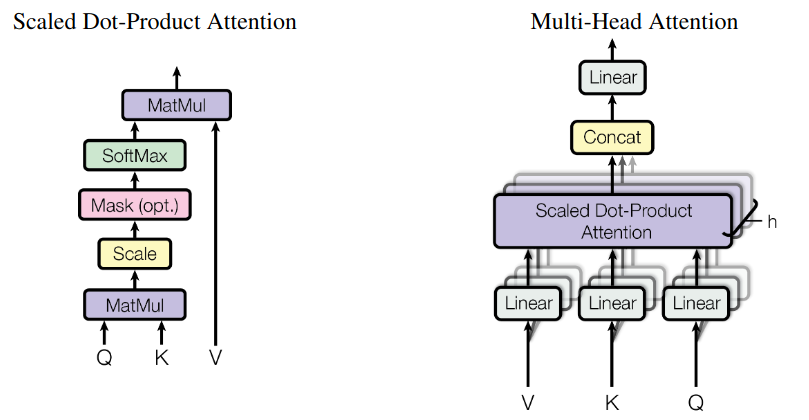

$$\text{Attention}(Q, K, V) = \text{softmax} \left( \frac{QK^T}{\sqrt{d_k}} \right) V $$

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, dim, n_heads, attn_pdrop, proj_pdrop):
        super().__init__()       
        self.dim = dim
        self.n_heads = n_heads
        
        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
        self.out_proj = nn.Linear(dim, dim)
        
        self.attn_dropout = nn.Dropout(attn_pdrop)
        self.proj_dropout = nn.Dropout(proj_pdrop)          

    def forward(self, q, k, v, mask=None):
        """
        all of q, k, v have similar shapes like [batch_size(B), sequence_length(L), embedding_dim(D)]
        The length (L) of k and v must be the same, but it does not necessarily have to match the length (L) of q. 
        The batch size and dimension must remain the same for all.
        - q: [B, L_q, D]
        - k: [B, L_k, D]
        - v: [B, L_k, D]
        """
        # in_porj
        q = self.q_proj(q)
        k = self.k_proj(k)
        v = self.v_proj(v)

        # split by multi-heads
        def split(x):
            B, L, D = x.shape
            return x.reshape(B, L, self.n_heads, D // self.n_heads).transpose(1, 2) # [B, n, L, D//n]  
        q = split(q) # [B, L_q, D] => [B, n, L_q, D//n]
        k = split(k) # [B, L_k, D] => [B, n, L_k, D//n]
        v = split(v) # [B, L_v(==L_k), D] => [B, n, L_v, D//n]
            
        # scaled dot attention
        # integrated: F.scaled_dot_product_attention()
        attn = (q @ k.transpose(-1, -2)) / torch.tensor(k.size(-1)).sqrt()  # [B, n, L, D//n] @ [B, n, D//n, L] => [B, n, L, L]
        if mask is not None:
            # print(attn.shape, mask.shape)
            attn.masked_fill_(mask == 0, -100000)# can't use float('-inf'), caz it'll lead to a nan value
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_dropout(attn)
        out = attn @ v # [B, n, L, L] @ [B, n, L, D//n] => [B, n, L, D//n]

        # put_proj
        B, L = out.size(0), out.size(2)
        out = out.transpose(1, 2).reshape(B, L, -1) # [B, L, D]
        out = self.out_proj(out)
        out = self.proj_dropout(out)
        
        return out, attn

torch.Size([1, 32, 128])
torch.Size([1, 32, 128])
torch.Size([1, 4, 32, 32])


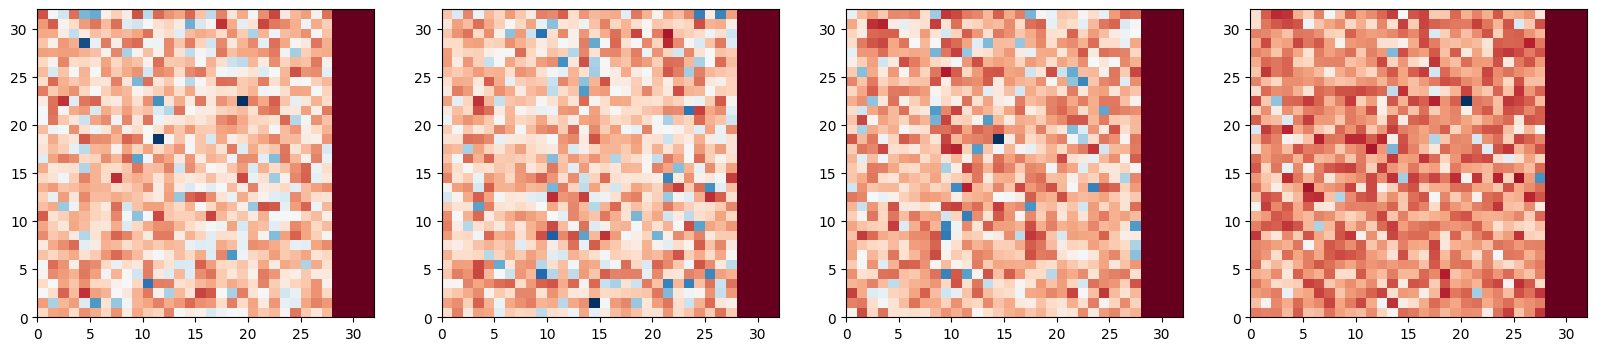

In [3]:
@torch.no_grad()
def test1():
    attn = MultiHeadAttention(128, 4, 0., 0.)
    x = torch.randn(1, 32, 128) # 32 sequence length with 128 dims
    mask = torch.tensor([1]*28 + [0]*4).unsqueeze(0)
    y, attn_val = attn(x, x, x, mask)
    print(x.shape)
    print(y.shape)
    print(attn_val.shape)

    #plot
    B, n, L, L = attn_val.shape
    attn_val = attn_val[0]
    fig, axes = plt.subplots(1, n, figsize=(20, 4))
    for i in range(n):
        ax = axes[i]
        ax.pcolormesh(attn_val[i], cmap='RdBu')
    plt.show()
    
    # print('pass! 🥂')

test1()

## Part2. Positional Embedding

$$
PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{\frac{2i}{d_{model}}}}\right)
$$

$$
PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{\frac{2i}{d_{model}}}}\right)
$$

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, dim):
        super().__init__()
        pos = torch.arange(max_len).float().unsqueeze(1)
        _2i = torch.arange(0, dim, step=2).float()
        
        weight = torch.zeros(max_len, dim)
        weight[:, 0::2] = torch.sin(pos / (10000 ** (_2i / dim)))
        weight[:, 1::2] = torch.cos(pos / (10000 ** (_2i / dim)))
        self.register_buffer('weight', weight) # auto register device, no gradient, persistable

    def forward(self, x):
        B, L = x.shape
        return self.weight[:L, :] # dim will auto broadcast

torch.Size([5, 50])
torch.Size([50, 128])


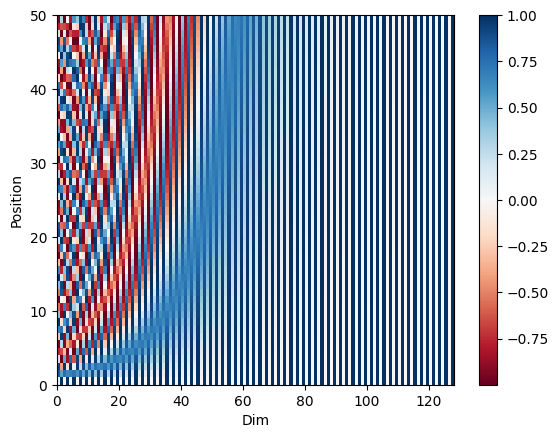

In [5]:
def test2():
    PE = PositionalEncoding(max_len=64, dim=128)
    x = torch.randint(0, 10000, (5, 50)) # batch=5, len=50
    print(x.shape)
    
    y = PE(x)
    print(y.shape)
    
    #plot
    plt.pcolormesh(y, cmap='RdBu')
    plt.xlabel('Dim')
    # plt.xlim((0, 32))
    plt.ylabel('Position')
    plt.colorbar()
    plt.show()

test2()

### Part3. Blocks and Transformer

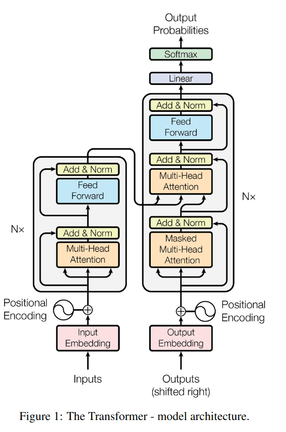

In [6]:
class FeedForward(nn.Module):
    def __init__(self, dim, h_dim, pdrop):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(dim, h_dim),
            nn.ReLU(),
            nn.Dropout(pdrop),
            nn.Linear(h_dim, dim),
        )

    def forward(self, x):
        return self.model(x)

In [7]:
class EncoderBlock(nn.Module):
    def __init__(self, dim, n_heads, ffn_dim, pdrop):
        super().__init__()
        self.attn = MultiHeadAttention(dim, n_heads, attn_pdrop=pdrop, proj_pdrop=pdrop)
        self.ffn = FeedForward(dim, ffn_dim, pdrop)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)

    def forward(self, x, mask):
        x = self.norm1(x + self.attn(x, x, x, mask)[0]) # attention returns Tuple(val, attn)
        x = self.norm2(x + self.ffn(x))
        return x

class DecoderBlock(nn.Module):
    def __init__(self, dim, n_heads, ffn_dim, pdrop):
        super().__init__()
        self.attn = MultiHeadAttention(dim, n_heads, attn_pdrop=pdrop, proj_pdrop=pdrop)
        self.cross_attn = MultiHeadAttention(dim, n_heads, attn_pdrop=pdrop, proj_pdrop=pdrop)
        self.ffn = FeedForward(dim, ffn_dim, pdrop)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.norm3 = nn.LayerNorm(dim)

    def forward(self, x, y, self_mask, cross_mask):
        # x: from decoder, y: from encoder
        x = self.norm1(x + self.attn(x, x, x, self_mask)[0])
        x = self.norm2(x + self.attn(x, y, y, cross_mask)[0])
        x = self.norm3(x + self.ffn(x))
        return x

In [8]:
class Transformer(nn.Module):
    def __init__(self, dim, n_layers, n_heads, ffn_dim, vocab_size, max_len, pdrop=0.1):
        super().__init__()
        assert dim % n_heads == 0
        self.encoder = nn.ModuleList(
            [EncoderBlock(dim, n_heads, ffn_dim, pdrop) for _ in range(n_layers)]
        )
        self.decoder = nn.ModuleList(
            [DecoderBlock(dim, n_heads, ffn_dim, pdrop) for _ in range(n_layers)]
        )
        self.classifier = nn.Linear(dim, vocab_size)
        self.wte = nn.Embedding(vocab_size, dim)    # token embeddings
        self.wpe = PositionalEncoding(max_len, dim) # position embeddings

        casual_mask = torch.tril(torch.ones(max_len, max_len)).type(torch.ByteTensor)
        self.register_buffer(
            'casual_mask', casual_mask.reshape(1, 1, max_len, max_len)
        )

    ### FIXME: this init method will lead to a much slower convergence.
    #     self.apply(self._init_weights)

    # def _init_weights(self, m):
    #     if hasattr(m, 'weight') and m.weight.dim() > 1:
    #         nn.init.kaiming_uniform_(m.weight.data)
    
    def forward(self, src, trg, src_mask, trg_mask):
        # calculate mask
        B, L = src.shape
        src_mask = src_mask.reshape(B, 1, 1, L) # padding mask
        B, L = trg.shape
        trg_mask = trg_mask.reshape(B, 1, L, 1) & self.casual_mask[:,:,:L,:L] # causual mask
        
        src_logits = self.wte(src) + self.wpe(src)
        for layer in self.encoder:
            src_logits = layer(x=src_logits, mask=src_mask)
        trg_logits = self.wte(trg) + self.wpe(trg)
        for layer in self.decoder:
            trg_logits = layer(x=trg_logits, y=src_logits, self_mask=trg_mask, cross_mask=src_mask)

        prob = self.classifier(trg_logits) # [B, L_trg, V]
        # prob = F.softmax(prob, dim=-1) # no softmax. see: https://blog.csdn.net/weixin_43457608/article/details/144021280
        
        return prob

### Part4. Demo: Crack the cipher

In [ ]:
import string

class MappingEncryptor():
    base = list(string.digits + string.ascii_lowercase + string.ascii_uppercase)
    def __init__(self, cipher):
        assert isinstance(cipher, list) and len(cipher) == len(self.base)
        self.token_id = {token: i for i, token in enumerate(self.base)}
        self.cipher = cipher
        self.decipher = {i_:i for i, i_ in enumerate(self.cipher)}

    @classmethod
    def generate_cipher(cls):
        import random
        n = len(cls.base)
        indeces_map = list(range(n))
        random.shuffle(indeces_map)
        return indeces_map
    
    def encrypt(self, input_str):
        map_fn = lambda x: self.base[self.cipher[self.token_id[x]]] if x in self.base else x
        return "".join([map_fn(x) for x in input_str])

    def decrypt(self, input_str):
        map_fn = lambda x: self.base[self.decipher[self.token_id[x]]] if x in self.base else x
        return "".join([map_fn(x) for x in input_str])

In [10]:
# create your cipher for the first run
# cipher = MappingEncryptor.generate_cipher()
# print(cipher)
cipher = [5, 58, 7, 6, 17, 13, 51, 46, 4, 8, 57, 47, 22, 44, 35, 50, 59, 18, 38, 29, 56, 27, 33, 24, 36, 42, 26, 43, 14, 60,
          37, 30, 3, 40, 20, 45, 9, 12, 53, 61, 11, 10, 54, 31, 49, 32, 48, 21, 28, 15, 1, 2, 19, 52, 39, 41, 23, 25, 34, 0, 55, 16]
encryptor = MappingEncryptor(cipher)
encryptor.encrypt("I love you !")

'N rAuz kAB !'

In [11]:
encryptor.decrypt("N rAuz kAB !")

'I love you !'

In [12]:
import random
from torch.utils.data import Dataset, DataLoader

class CryptDataset(Dataset):
    def __init__(self, data, encryptor, captial_p):
        self.data = data
        self.encryptor = encryptor
        self.captial_p = captial_p

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        plain = self.data[idx]
        if random.random() < self.captial_p:
            plain = plain.upper()
        crypt = self.encryptor.encrypt(plain)
        return crypt, plain


class CryptTokenizer():
    def __init__(self):
        self.special = ['[BOS]', '[EOS]', '[PAD]', '[UNK]', '.', ',', ' ']
        self.base = self.special + MappingEncryptor.base
        self.token_id = {token: i for i, token in enumerate(self.base)}

    def token_to_id(self, token):
        return self.token_id[token] if token in self.token_id.keys() else self.token_id['[UNK]']

    def id_to_token(self, idx):
        assert idx < len(self.base), "id is out of range!"
        return self.base[idx]
    
    def get_vocab_size(self):
        return len(self.base)

    def encode(self, x):
        sentence = [self.token_to_id(a) for a in x]
        sentence = torch.tensor([self.token_to_id('[BOS]')] + sentence + [self.token_to_id('[EOS]')])
        return dict(
            ids = sentence,
            mask = sentence != self.token_to_id('[PAD]')
        )
        
    def decode(self, x):
        # mapping = lambda x: self.base[x] if x in self.token_to_id.values() else '[UNK]'
        return "".join([self.id_to_token(a) for a in x])

    def batch_encode(self, batch):
        encoded_batch = [self.encode(sentence) for sentence in batch]
        max_length = max(seq["ids"].size(0) for seq in encoded_batch)
        pad_id = self.token_to_id('[PAD]')
        
        padded_ids = torch.stack([
            torch.cat([seq["ids"], torch.full((max_length - seq["ids"].size(0),), pad_id)]) for seq in encoded_batch
        ])
        
        padded_mask = padded_ids != pad_id
        
        return dict(
            ids=padded_ids,
            mask=padded_mask
        )

In [13]:
tokenizer = CryptTokenizer()
code = tokenizer.batch_encode(
    ['I love you!!!', 'I love you, too!']
)
print(code)
print(tokenizer.decode(code['ids'][0]))

{'ids': tensor([[ 0, 51,  6, 28, 31, 38, 21,  6, 41, 31, 37,  3,  3,  3,  1,  2,  2,  2],
        [ 0, 51,  6, 28, 31, 38, 21,  6, 41, 31, 37,  5,  6, 36, 31, 31,  3,  1]]), 'mask': tensor([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True,  True, False, False, False],
        [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True,  True,  True,  True,  True]])}
[BOS]I love you[UNK][UNK][UNK][EOS][PAD][PAD][PAD]


In [14]:
vocab_size = tokenizer.get_vocab_size()
vocab_size

69

Since now we have make a tiny toy dataset which translates English sentences by letters, and we also make a tokenizer so that we can easily tokenizer all of the texts. Let's train a tiny transformer at this tiny dataset afterwards.

In [15]:
import json
with open('./data/en.json', 'r') as f:
    data = json.load(f)

dataset = CryptDataset(data, encryptor, captial_p=0.3)
dataset[0]

('"N l1pb T1n 9RQ1DD Fvb QNpbQ 9fZ 1pbQ Fvb vNllD, " D9NZ cNS fnFcQ1yf v9Qb.',
 '"I LOVE YOU ACROSS THE RIVER AND OVER THE HILLS, " SAID BIG NUTBROWN HARE.')

In [16]:
# model parameter setting
max_len = 256
d_model = 64
n_layers = 3
n_heads = 4
ffn_hidden = 256
drop_prob = 0.1

# optimizer parameter setting
init_lr = 1e-3
warmup = 100
inf = float('inf')

# data setting
num_epoch = 20
batch_size = 32

In [17]:
from tqdm import tqdm
from torch.optim import Adam, lr_scheduler
from torch.utils.data import DataLoader

torch.cuda.empty_cache() # release CUDA mem
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


transformer = Transformer(
    dim=d_model,
    n_layers=n_layers,
    n_heads=n_heads,
    ffn_dim=ffn_hidden,
    max_len=max_len,
    vocab_size=vocab_size,
    pdrop=drop_prob
).to(device)
optimizer = Adam(
    params=transformer.parameters(),
    lr=init_lr,
    # weight_decay=weight_decay,
    # eps=adam_eps
)

train_loader = DataLoader(dataset, batch_size=batch_size, num_workers=4, persistent_workers=True)

acc = 0
with tqdm(total=num_epoch*len(train_loader)) as pbar:
    for epoch in range(num_epoch):
        # train
        pbar.set_description(f'Epoch {epoch+1}')
        transformer.train()
        for src, trg in train_loader:
            src = tokenizer.batch_encode(src)
            trg = tokenizer.batch_encode(trg)
            prob = transformer(
                src=src['ids'].to(device),
                trg=trg['ids'][:,:-1].to(device),
                src_mask=src['mask'].to(device),
                trg_mask=trg['mask'][:,:-1].to(device),
            )
            predict = prob.reshape(-1, prob.size(-1))
            truth = trg['ids'][:,1:].contiguous().view(-1).to(device)
            loss = F.cross_entropy(predict, truth, ignore_index=tokenizer.token_to_id('[PAD]'), reduction='mean') # ignore pad
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            pbar.set_postfix(loss=f"{loss.item():.4f}")
            pbar.update(1)
        if epoch % 2 == 1:  
            torch.save(transformer, f'epoch-{epoch+1}.pt')

Epoch 20: 100%|████████████████| 6260/6260 [19:04<00:00,  5.47it/s, loss=0.0018]


In [18]:
# transformer = torch.load('epoch-20.pt')
transformer.eval()

@torch.no_grad()
def generate(src, max_output_len=64, verbose=False):
    src = tokenizer.batch_encode([src])
    in_ids = src['ids'].to(device)
    in_mask = src['mask'].to(device)
    out_ids = torch.tensor([[tokenizer.token_to_id("[BOS]")]]).to(device)
    out_mask = torch.tensor([[1]]).to(device)
    
    while tokenizer.token_to_id("[EOS]") != out_ids[0,-1] and out_ids.size(1) <= max_output_len:
        if verbose:
            print(tokenizer.decode(out_ids.squeeze(0).cpu().tolist()))
        
        prob = transformer(in_ids, out_ids, in_mask, out_mask)
        # print(prob.shape)
        # topk_values, topk_indices = torch.topk(prob, k=3, dim=-1)
        # print(topk_values, topk_indices)
        next_token = torch.argmax(prob[:,-1,:], dim=-1)
        # print(out_ids.shape, next_token.shape)
        out_ids = torch.cat([out_ids, next_token.unsqueeze(0)], dim=1)
        out_mask = torch.cat([out_mask, torch.tensor([[1]]).to(device)], dim=0)
        # print(out_ids.cpu())
    print(tokenizer.decode(out_ids.squeeze(0).cpu().tolist()))
generate('N rAuz kAB !', max_output_len=20, verbose=True)  

[BOS]
[BOS]I
[BOS]I 
[BOS]I l
[BOS]I lo
[BOS]I lov
[BOS]I love
[BOS]I love 
[BOS]I love y
[BOS]I love yo
[BOS]I love you
[BOS]I love you 
[BOS]I love you [UNK]
[BOS]I love you [UNK][EOS]


In [19]:
generate(encryptor.encrypt('The quick brown fox jumps over a lazy dog.'), verbose=False) 
generate(encryptor.encrypt('THE QUICK BROWN FOX JUMPS OVER A LAZY DOG.'), verbose=False) 
generate(encryptor.encrypt('0123456789'), verbose=False) 

[BOS]The quick brown fox jumps over a lazy dog.[EOS]
[BOS]THE QUICK BROWN FOX JUMPS OVER A LAZY DOG.[EOS]
[BOS]0123456789[EOS]
